# GSE193531 — Step 2: Normalization and Per-Cohort Preprocessing

Loads the QC-filtered AnnData object, backs up raw counts, normalizes and
log1p-transforms the full gene set, flags highly variable genes (`seurat_v3`,
computed on raw counts), computes a per-cohort PCA/UMAP/Leiden clustering as a
sanity check (and as the input to unbiased marker discovery used by step 3),
and saves the normalized object.

**Input:**
- `data/processed/GSE193531/GSE193531_filtered.h5ad` (from notebook 01)
- `results/GSE193531/qc/GSE193531_cell_qc_filtered.csv`

**Output:**
- `data/processed/GSE193531/GSE193531_normalized.h5ad`
- `results/GSE193531/preprocessing/GSE193531_leiden_cluster_summary.csv`

One step here is a deliberate, documented judgment call, not a mechanical
computation: flagging specific Leiden clusters as non-plasma contaminants or
QC-caution (`cell_type_candidate`). Leiden clustering is stochastic — cluster
numbers from a fresh run will not match any numbers recorded in an earlier run
of this notebook, so no specific cluster IDs are hardcoded here. Instead, this
notebook ships a conservative default (no clusters flagged) and prints the
evidence (per-cluster top marker genes, QC metrics) needed to review and edit
`MYELOID_CLUSTERS` / `B_CELL_CLUSTERS` / `QC_CAUTION_CLUSTERS` below before
trusting `cell_type_candidate` for anything beyond the sanity-check role it
plays in step 3.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

sc.settings.verbosity = 1

#### Directory layout and required files

In [2]:
PROJECT = Path("../")
COHORT = "GSE193531"

PROCESSED_DIR = PROJECT / "data" / "processed" / COHORT
RESULTS_DIR = PROJECT / "results" / COHORT

(RESULTS_DIR / "preprocessing").mkdir(parents=True, exist_ok=True)

INPUT_H5AD = PROCESSED_DIR / f"{COHORT}_filtered.h5ad"
INPUT_QC_CSV = RESULTS_DIR / "qc" / f"{COHORT}_cell_qc_filtered.csv"

if not INPUT_H5AD.exists():
    raise FileNotFoundError(INPUT_H5AD)
if not INPUT_QC_CSV.exists():
    raise FileNotFoundError(INPUT_QC_CSV)

OUTPUT_H5AD = PROCESSED_DIR / f"{COHORT}_normalized.h5ad"

N_TOP_GENES = 3000
MIN_CELLS_FOR_BATCHED_HVG = 500

## Load Filtered Count Matrix and Re-Attach QC Columns

`sample_id`, `patient_id`, `clinical_stage_standard`, `n_genes`,
`doublet_score`, and `predicted_doublet` are already on `adata.obs` from
notebook 01; the remaining QC metrics (`n_counts`, `pct_mito`, `pct_ribo`,
`pct_hb`, `pct_ig`, `complexity`) are re-attached from the QC table rather
than recomputed.

In [3]:
adata = sc.read_h5ad(INPUT_H5AD)

qc_filtered = pd.read_csv(INPUT_QC_CSV, index_col=0)

if not qc_filtered.index.equals(adata.obs_names):
    raise ValueError("QC table index does not match AnnData cell order. Do not proceed until this is resolved.")

extra_qc_cols = ["n_counts", "pct_mito", "pct_ribo", "pct_hb", "pct_ig", "complexity"]
adata.obs = adata.obs.join(qc_filtered[extra_qc_cols])

print(adata)

AnnData object with n_obs × n_vars = 26953 × 22273
    obs: 'sample_id', 'patient_id', 'clinical_stage_standard', 'n_genes', 'doublet_score', 'predicted_doublet', 'n_counts', 'pct_mito', 'pct_ribo', 'pct_hb', 'pct_ig', 'complexity'
    uns: 'scrublet'


## Preserve Raw Counts, Normalize, Log-Transform

Raw counts are copied to `adata.layers["counts"]` before any transformation
(a sanity check confirms `.X` is still integer-valued at this point). Then
library-size normalization (target sum 1e4) and `log1p`.

In [4]:
sample = adata.X[:500].toarray() if hasattr(adata.X, "toarray") else np.asarray(adata.X[:500])
if not np.allclose(sample, np.round(sample)):
    raise ValueError("adata.X does not look like raw counts (non-integer values found). Aborting.")

adata.layers["counts"] = adata.X.copy()
print('Raw counts backed up to adata.layers["counts"]')

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print("Normalized and log1p-transformed. adata.X now holds log-normalized values.")

Raw counts backed up to adata.layers["counts"]
Normalized and log1p-transformed. adata.X now holds log-normalized values.


## Highly Variable Genes

`seurat_v3` fits its own mean-variance model and needs **raw counts** —
pointed explicitly at `adata.layers["counts"]`, not `adata.X`. Genes are
selected per sample (`batch_key="sample_id"`) when every sample has enough
cells; otherwise this falls back to a single cohort-wide fit. Genes are
flagged in `adata.var["highly_variable"]` only, **not subsetted** — the full
gene set stays available downstream.

In [5]:
min_cells_per_sample = int(adata.obs["sample_id"].value_counts().min())
use_batch_key = min_cells_per_sample >= MIN_CELLS_FOR_BATCHED_HVG

hvg_kwargs = dict(n_top_genes=N_TOP_GENES, flavor="seurat_v3", layer="counts", subset=False)

try:
    sc.pp.highly_variable_genes(adata, batch_key="sample_id" if use_batch_key else None, **hvg_kwargs)
except ValueError as exc:
    print(f"Per-sample HVG fit failed ({exc!r}); falling back to a single cohort-wide fit.")
    sc.pp.highly_variable_genes(adata, batch_key=None, **hvg_kwargs)

n_hvg = int(adata.var["highly_variable"].sum())
batch_fit_status = "used" if use_batch_key else "skipped"
print(f"Smallest sample has {min_cells_per_sample:,} cells (batched fit {batch_fit_status}).")
print(f"Flagged {n_hvg:,} / {adata.n_vars:,} genes as highly variable (target {N_TOP_GENES:,}).")

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Smallest sample has 26 cells (batched fit skipped).
Flagged 3,000 / 22,273 genes as highly variable (target 3,000).


## PCA, Neighbors, UMAP, Leiden Clustering (Per-Cohort Sanity Check)

PCA is computed on a **separate scaled copy** of the HVG subset — `adata.X`
itself is never overwritten. The PCA embedding is attached back onto the full
`adata` object, and neighbors/UMAP/Leiden are computed from it.

In [6]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10)

n_comps = min(50, adata_hvg.n_vars - 1)
sc.tl.pca(adata_hvg, svd_solver="arpack", n_comps=n_comps)

adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
adata.uns["pca"] = adata_hvg.uns["pca"]

n_pcs = min(30, n_comps)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep="X_pca")
sc.tl.umap(adata, min_dist=0.5)
sc.tl.leiden(adata, resolution=1.0)

print(f"PCA: {n_comps} components on {adata_hvg.n_vars:,} HVGs")
print(f"Leiden clusters: {adata.obs['leiden'].nunique()}")

/Users/razieyousefi/.local/share/virtualenvs/scheduler-VvWwxyw_/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-27 12:49:59.583818: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/var/folders/9t/94_h43_d2fn3wr53_k5zf2gh0000gn/T/ipykernel_3884/4040157953.py:13: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=1.0)


PCA: 50 components on 3,000 HVGs
Leiden clusters: 26


## UMAP Diagnostics

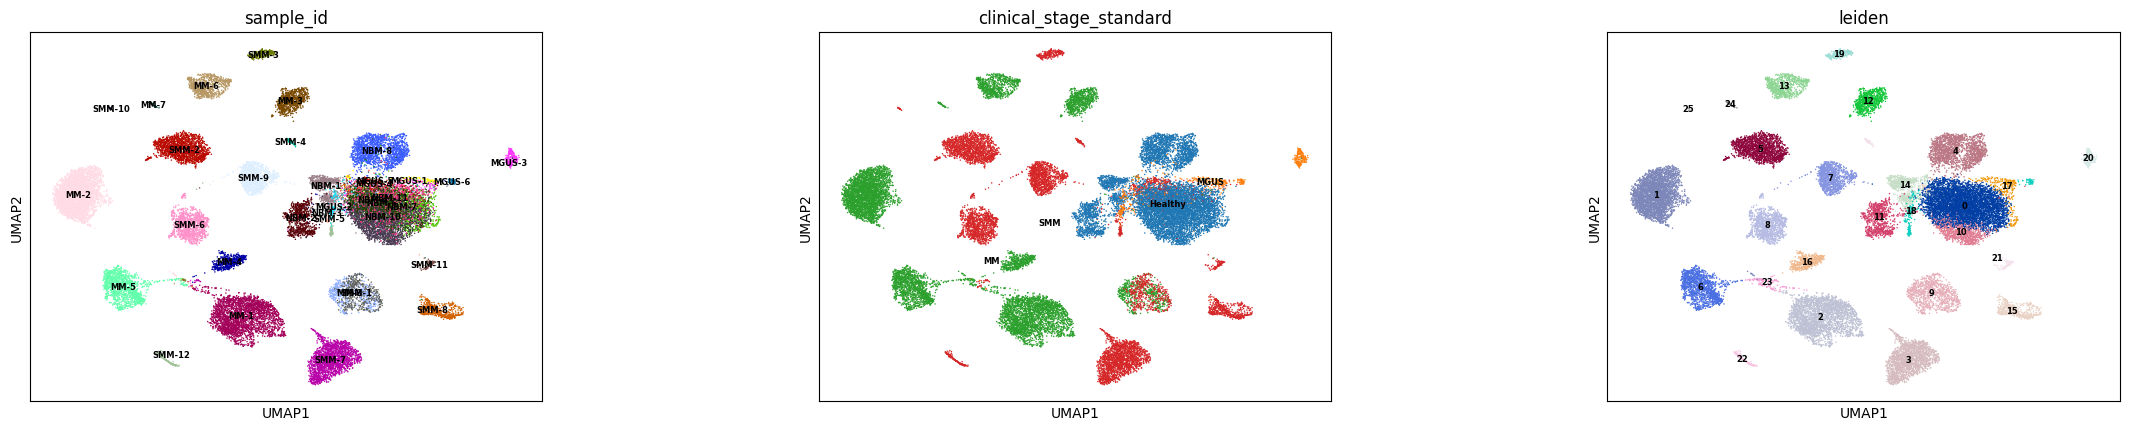

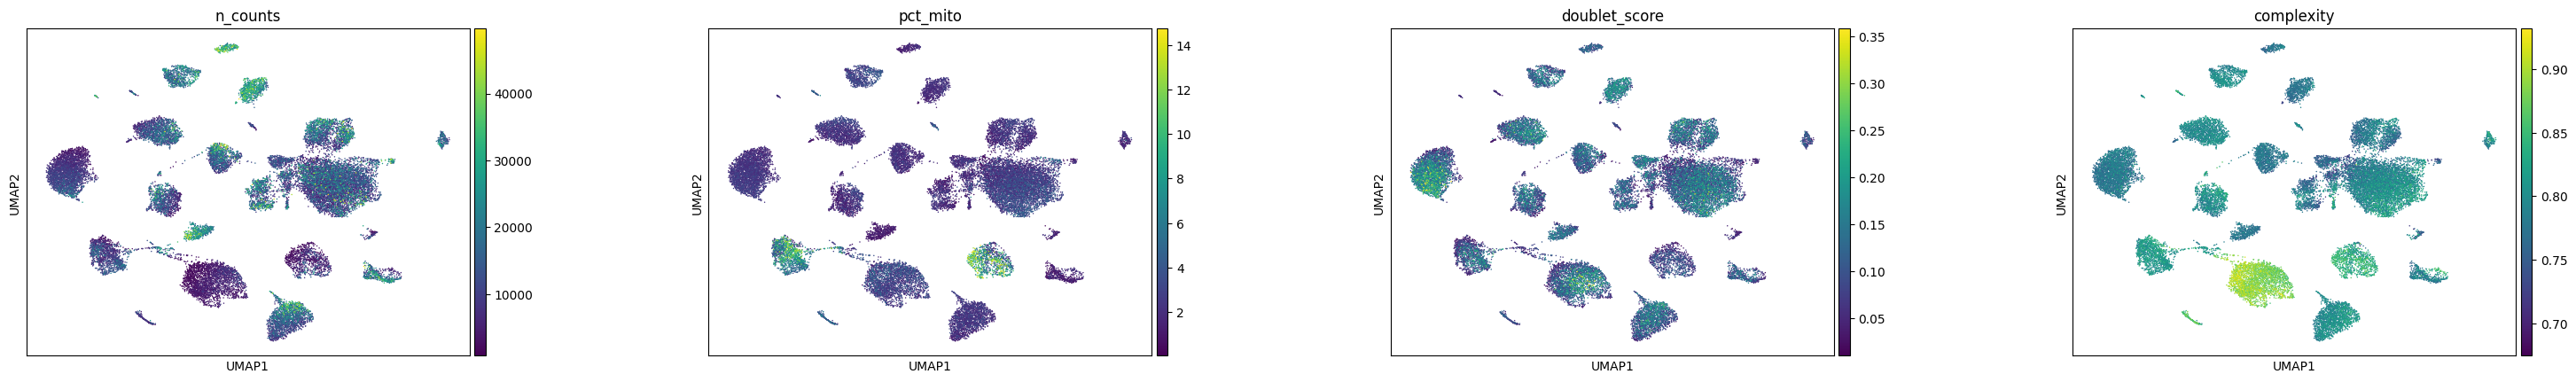

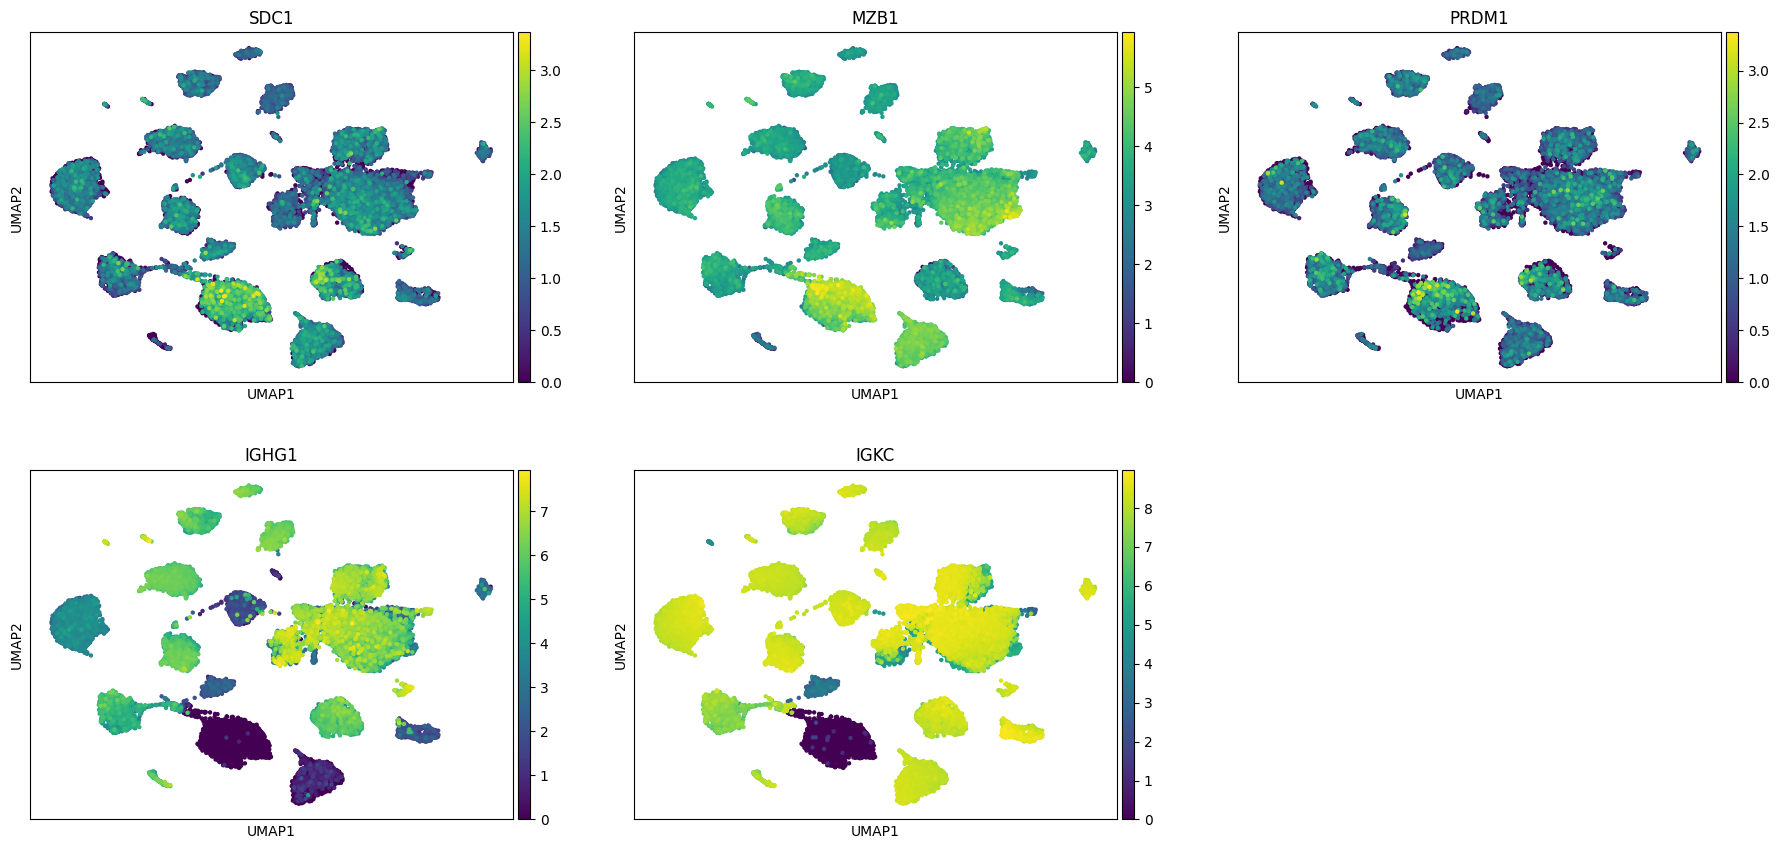

In [7]:
sc.pl.umap(adata, color=["sample_id", "clinical_stage_standard", "leiden"], wspace=0.4, legend_loc="on data", legend_fontsize=6)
sc.pl.umap(adata, color=["n_counts", "pct_mito", "doublet_score", "complexity"], wspace=0.4, cmap="viridis")

marker_genes_umap = ["SDC1", "MZB1", "PRDM1", "IGHG1", "IGKC"]
available_markers = [g for g in marker_genes_umap if g in adata.var_names]
missing_markers = [g for g in marker_genes_umap if g not in adata.var_names]
if missing_markers:
    print("Markers not found in this cohort:", missing_markers)
if available_markers:
    sc.pl.umap(adata, color=available_markers, ncols=3, size=40, cmap="viridis")

## Cluster Annotation QC

Unbiased per-cluster marker discovery first (`rank_genes_groups`, kept in
`adata.uns` for step 3's DE cross-check), then a curated marker dotplot
including negative-control markers for the cell types most likely to be
confused with each other, then a sample-composition check before trusting any
single-sample-dominated cluster as biology rather than a batch artifact.

In [8]:
display(adata.obs["leiden"].value_counts().sort_index())

sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
top_markers = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(10)
top_markers

leiden
0     5062
1     3191
2     2667
3     1947
4     1684
5     1574
6     1356
7     1111
8     1074
9      960
10     836
11     817
12     735
13     729
14     696
15     576
16     498
17     248
18     234
19     227
20     195
21     178
22     163
23     121
24      47
25      27
Name: count, dtype: int64

/Users/razieyousefi/.local/share/virtualenvs/scheduler-VvWwxyw_/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:435: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/Users/razieyousefi/.local/share/virtualenvs/scheduler-VvWwxyw_/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:437: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/Users/razieyousefi/.local/share/virtualenvs/scheduler-

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,IGLC3,IGHV3-20,IGLV2-8,IGHV3-21,S100A9,IGKV1-9,RPS16,IGHV1-18,CCND1,ITGB7,...,IGLV1-47,CD79A,CCND1,IGHV3-30,IGKV1-12,IGKV3-20,HLA-DRB1,STMN1,IGHV3-15,IGLV2-11
1,IGHD,IGHV3-43,IGLL5,CST3,S100A8,IGHV4-59,RPL28,IGHA2,IGKV1-39,AC233755.2,...,HBA2,CD27,AC090498.1,FRZB,IGKV1-39,IGKV3D-11,HLA-DRA,HMGB2,IGKV3-11,IGLL1
2,CD27,IGKV2D-28,CD74,SSR4,IGHG2,IGHG4,RPL18A,AL928768.3,IGHV3-11,MT-ATP6,...,IGHD,LSP1,NBEAL1,IGKV1D-33,IGHV3-11,IGKV3-11,HLA-DPA1,TUBA1B,IGHGP,IGLL5
3,IGLC2,RPL36A,HLA-A,IGKV1-9,XIST,IGHG3,RPS28,JCHAIN,JCHAIN,IGKV3-15,...,LAG3,TMSB4X,ZNF90,IGHGP,IGHG4,IGKV3D-20,HLA-DQA1,HMGN2,LAMP5,IGHV1-69-2
4,IGHA1,RPL34,MTDH,AL928768.3,IGHG4,GLTSCR2,RPS19,CCND1,IGHG3,MT-CYB,...,IGLC2,CD99,TXNDC5,RPL23A,CST6,AC090498.1,CD74,TUBB,KRTCAP2,IGLC7
5,IGLV3-21,RPS3A,HLA-B,TIMP1,IGLC3,RPLP2,RPL3,IGHA1,IGKV1-12,IGHGP,...,IFI6,HCST,IGHG3,EEF1A1,RP11-598F7.3,NBEAL1,HLA-DPB1,H2AFZ,IGHG2,IGLC6
6,H3F3B,RPL39,HLA-C,IGHA1,IGHM,XIST,GNB2L1,RGS1,RP5-887A10.1,MT-CO1,...,PTP4A3,PDIA4,JUND,NUDT12,SOCS3,RPL17,RP5-887A10.1,HMGB1,IGHG1,IGHGP
7,IGHM,RPL8,SNHG25,IGHA2,IGKV3-20,FXYD5,RPL36,RGS13,IGHG4,NEAT1,...,KIAA0125,MT-CO1,IGHV3-11,BTBD3,KLF2,IFITM1,HLA-DMA,PTMA,AC090498.1,IGLC5
8,IGHG2,RPS6,SPCS2,AZGP1,IGKV4-1,RPS11,RPL13A,RP11-211G23.2,TSC22D3,MT-ND1,...,HBA1,SUB1,RPL17,GADD45A,HIST1H1C,ZNF90,CCND1,H3F3A,DERL3,ZNF90
9,HERPUD1,RPS13,PDIA6,TMEM59,IGLC7,RPL4,RPS15,CYBA,COMMD3,LILRB4,...,HLA-B,PPIB,UBC,HLA-C,IGKV1D-39,RPL36A,HLA-DRB5,HIST1H4C,QPCT,IGHG1


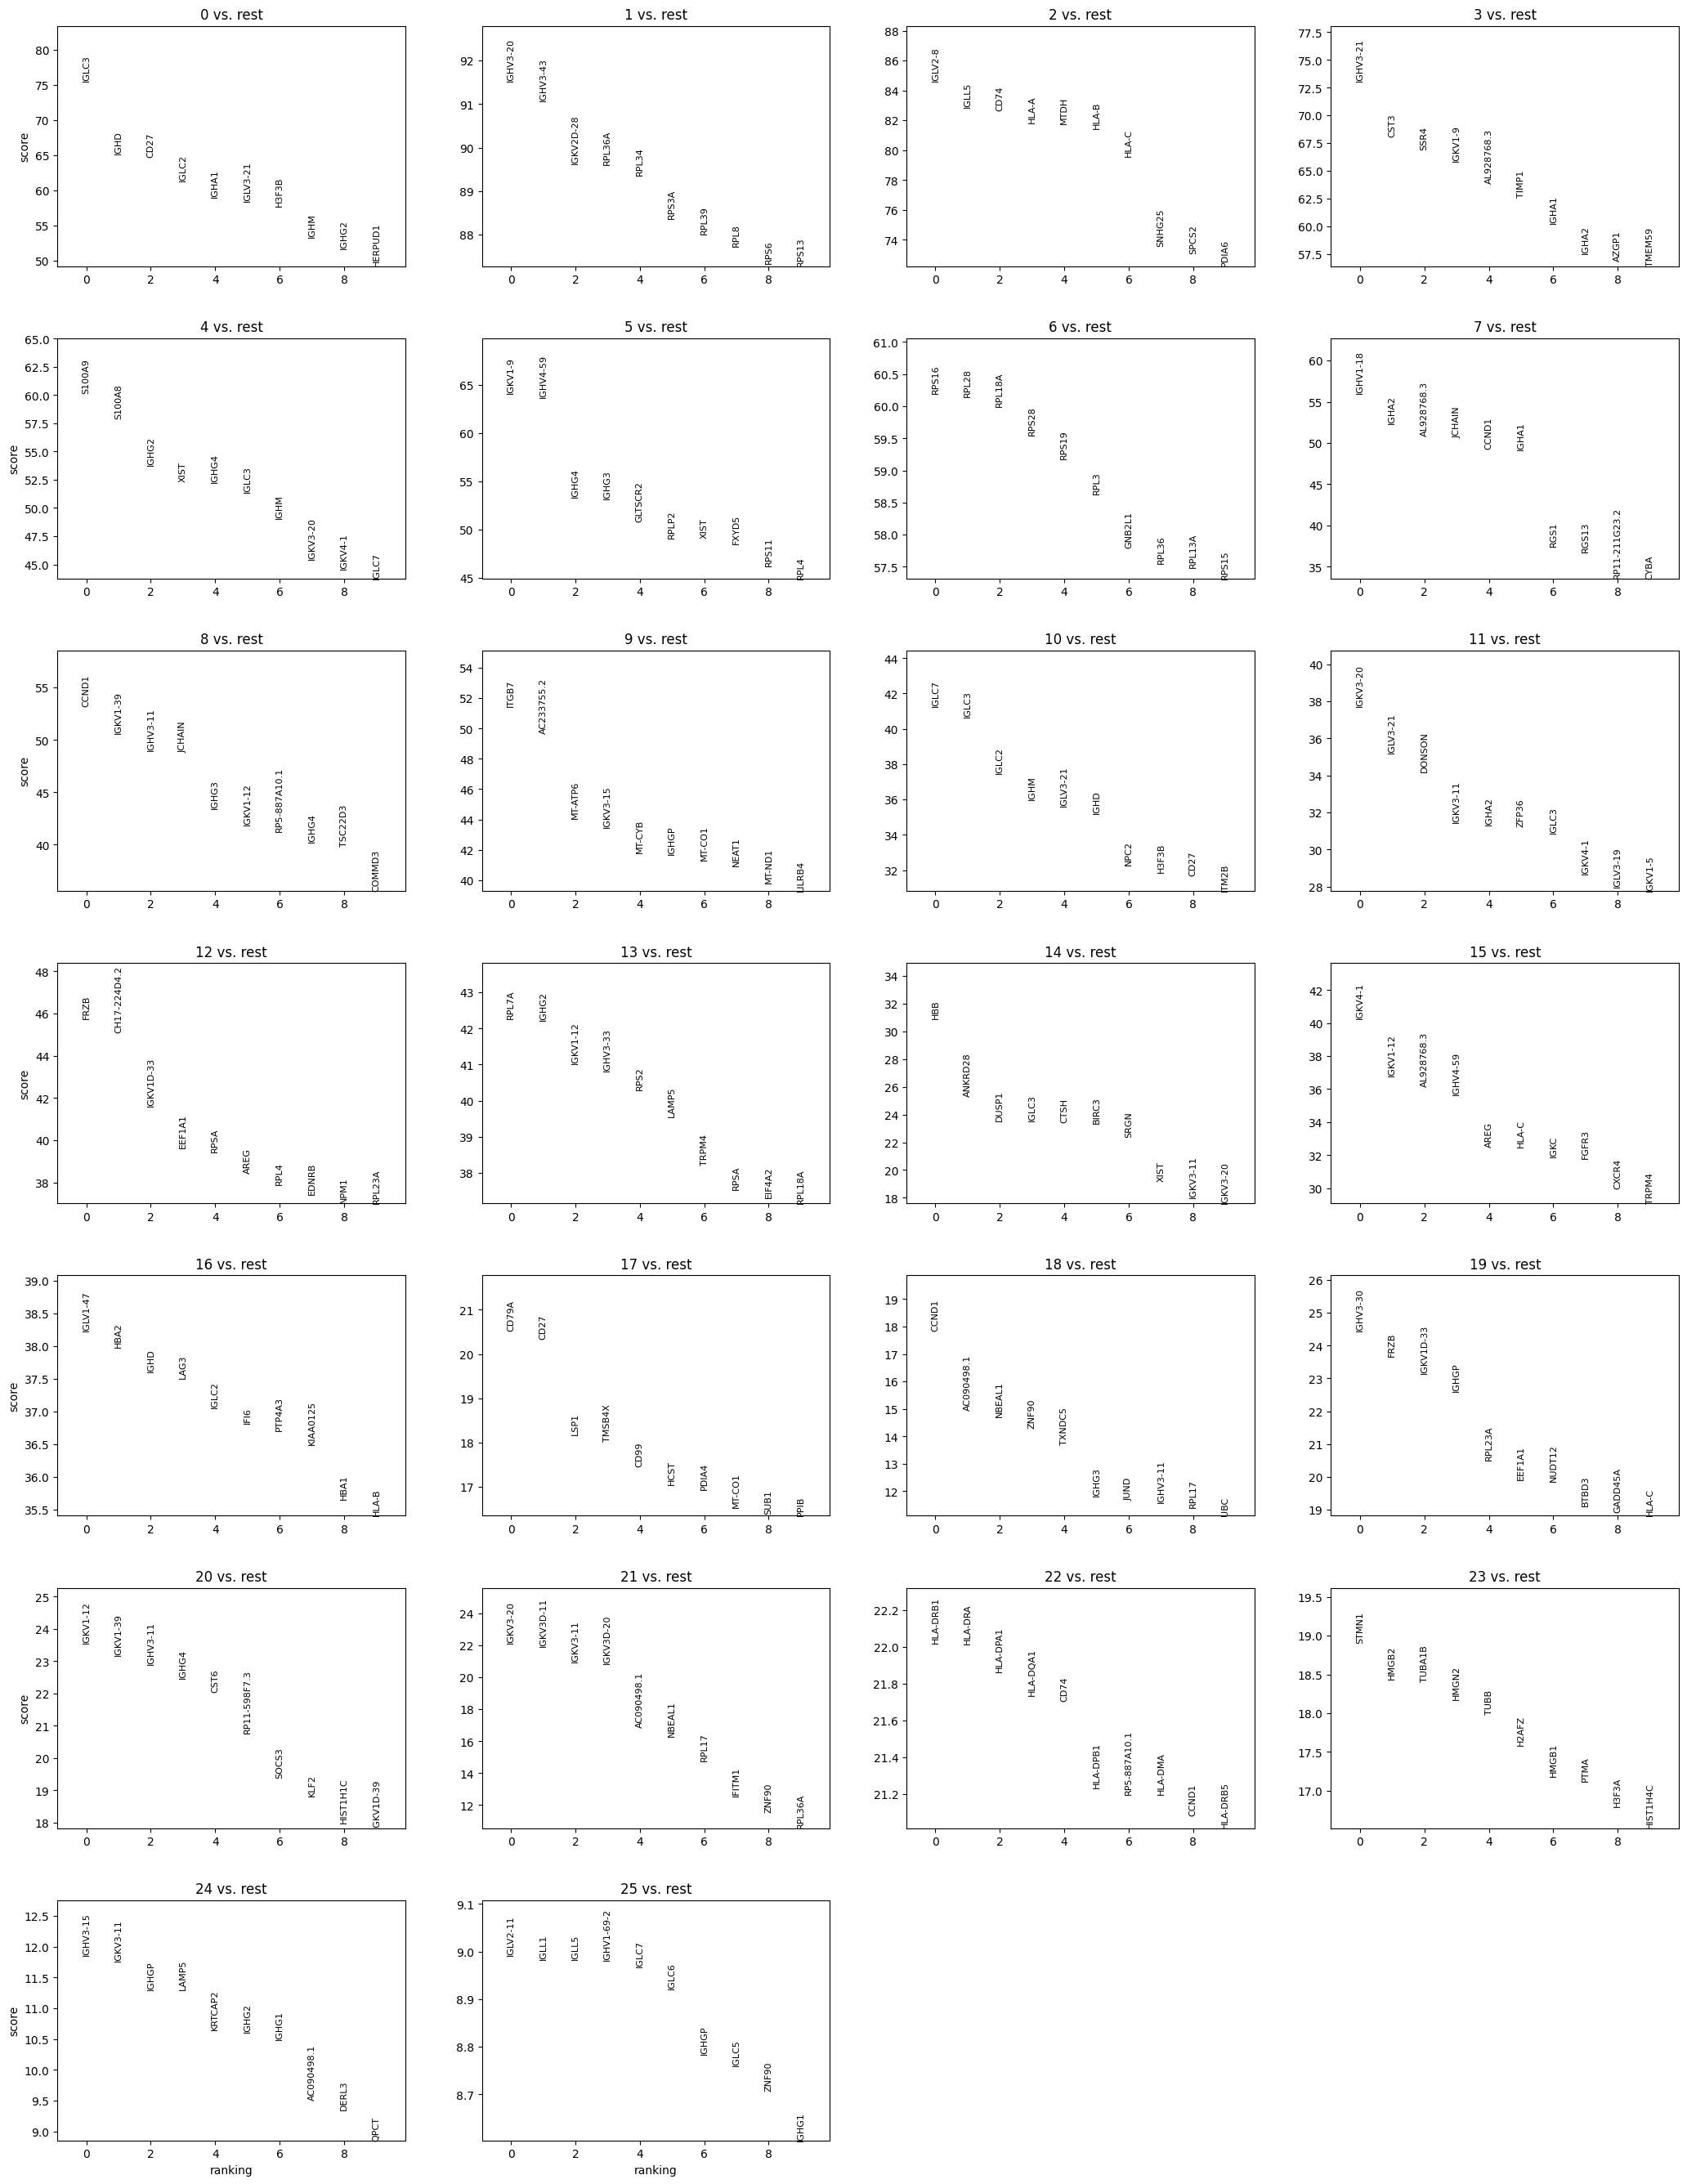

In [9]:
sc.pl.rank_genes_groups(adata, n_genes=10, sharey=False)

### QC Metrics per Cluster

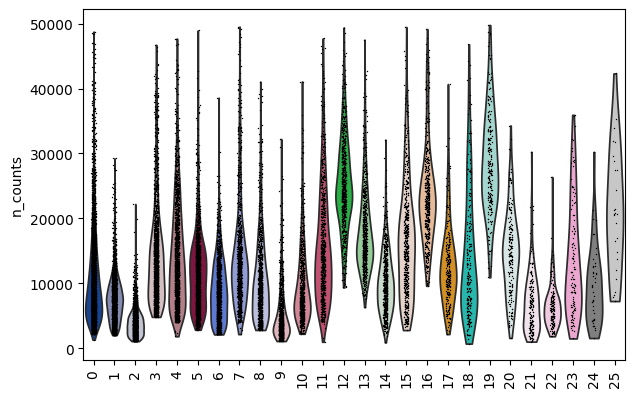

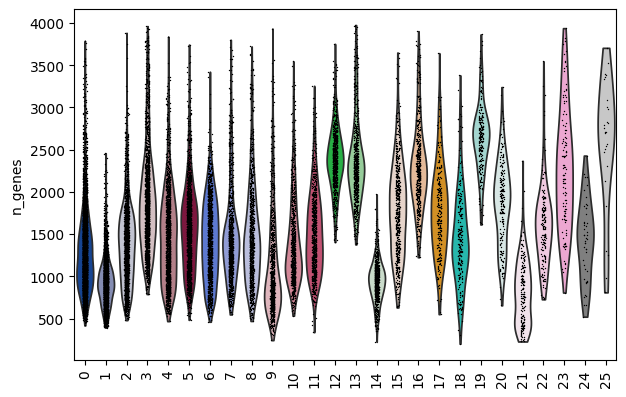

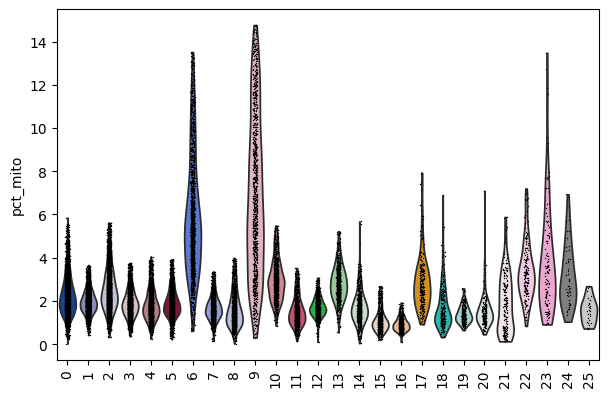

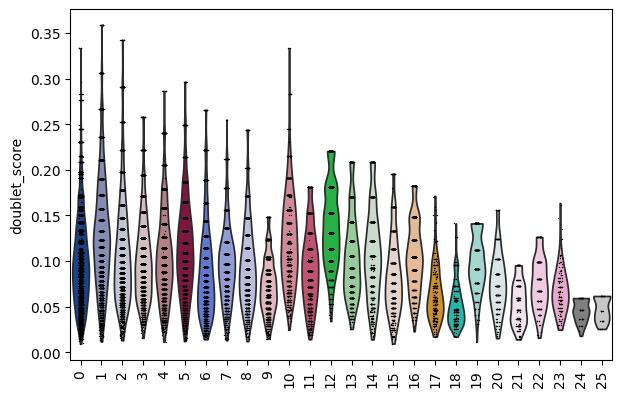

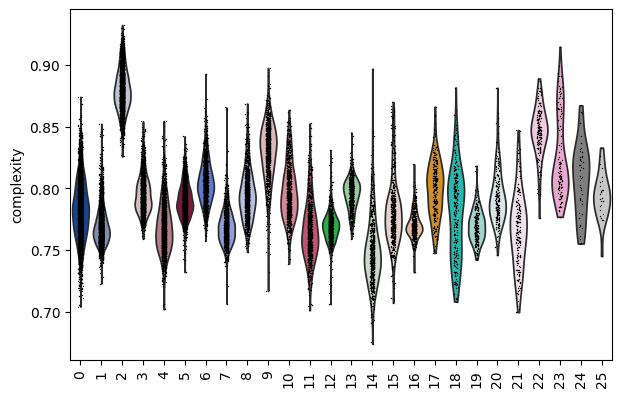

In [10]:
qc_metrics = ["n_counts", "n_genes", "pct_mito", "doublet_score", "complexity"]
for metric in qc_metrics:
    sc.pl.violin(adata, metric, groupby="leiden", rotation=90)

### Curated Marker Dotplot

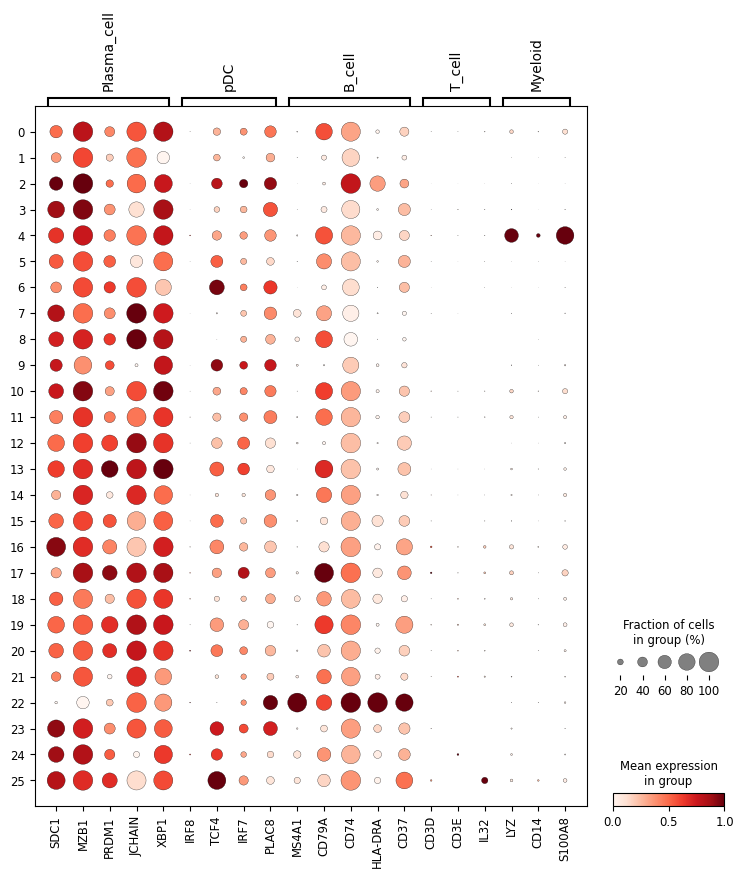

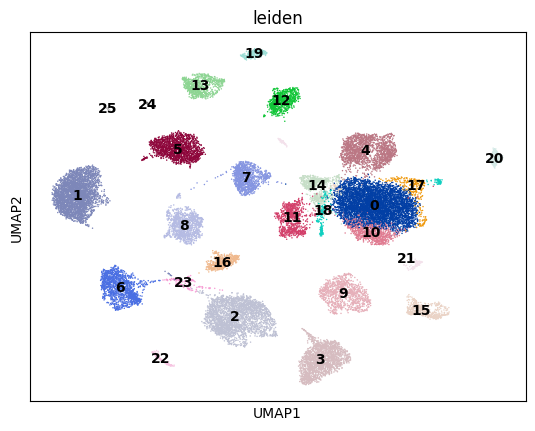

In [11]:
marker_genes = {
    "Plasma_cell": ["SDC1", "MZB1", "PRDM1", "JCHAIN", "XBP1"],
    "pDC": ["IRF8", "TCF4", "IRF7", "PLAC8"],
    "B_cell": ["MS4A1", "CD79A", "CD74", "HLA-DRA", "CD37"],
    "T_cell": ["CD3D", "CD3E", "IL32"],
    "Myeloid": ["LYZ", "CD14", "S100A8"],
}

sc.pl.dotplot(adata, marker_genes, groupby="leiden", standard_scale="var")
sc.pl.umap(adata, color="leiden", legend_loc="on data")

### Cluster Classification — Review and Edit

Review the dotplot, the unbiased `rank_genes_groups` output, and the
per-cluster QC-metric violins above. Then edit the three lists below so every
cluster this run produced is correctly categorized. The default is
conservative and does **not** reflect a completed review: nothing is flagged
until you edit it.

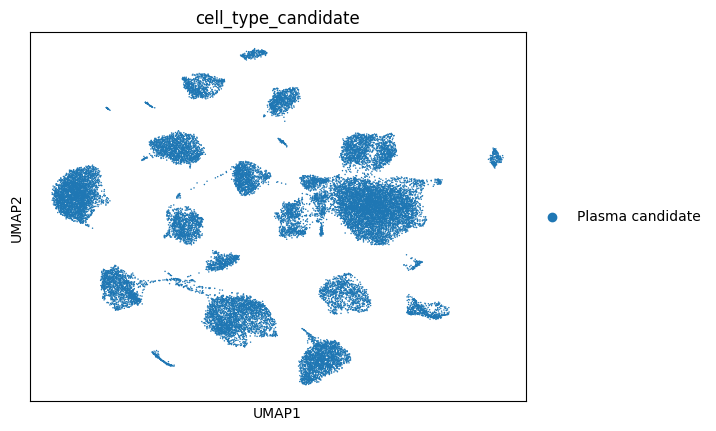

cell_type_candidate
Plasma candidate    26953
Name: count, dtype: int64

In [12]:
# --- EDIT AFTER REVIEWING the evidence above. Every observed cluster ID should be considered. ---
MYELOID_CLUSTERS = []
B_CELL_CLUSTERS = []
QC_CAUTION_CLUSTERS = []
# --- end of editable block ---

adata.obs["cell_type_candidate"] = np.select(
    [
        adata.obs["leiden"].isin(MYELOID_CLUSTERS),
        adata.obs["leiden"].isin(B_CELL_CLUSTERS),
        adata.obs["leiden"].isin(QC_CAUTION_CLUSTERS),
    ],
    ["Myeloid candidate", "B cell candidate", "QC-caution (low counts / high mito)"],
    default="Plasma candidate",
)

sc.pl.umap(adata, color="cell_type_candidate")
adata.obs["cell_type_candidate"].value_counts()

### Sample Composition of the Flagged Clusters

Does a flagged cluster reflect one sample's biology, or a broader batch
effect touching that sample's other clusters too?

In [13]:
flagged_clusters = sorted(set(MYELOID_CLUSTERS) | set(B_CELL_CLUSTERS) | set(QC_CAUTION_CLUSTERS))
if flagged_clusters:
    flagged_samples = (
        adata.obs.loc[adata.obs["leiden"].isin(flagged_clusters), "sample_id"]
        .value_counts().head(10).index.tolist()
    )
    display(
        pd.crosstab(adata.obs["sample_id"], adata.obs["leiden"], normalize="index")
        .loc[flagged_samples].round(3)
    )
else:
    print("No clusters flagged -- nothing to check here yet.")

No clusters flagged -- nothing to check here yet.


## Save Normalized AnnData

In [14]:
adata.write(OUTPUT_H5AD)

cluster_summary = (
    adata.obs.groupby(["leiden", "clinical_stage_standard"], observed=True)
    .size().rename("n_cells").reset_index()
)
cluster_summary_path = RESULTS_DIR / "preprocessing" / f"{COHORT}_leiden_cluster_summary.csv"
cluster_summary.to_csv(cluster_summary_path, index=False)

n_leiden_clusters = adata.obs["leiden"].nunique()

print(f"Saved normalized AnnData: {OUTPUT_H5AD}")
print(f"Cells: {adata.n_obs:,}  Genes: {adata.n_vars:,}  HVGs: {n_hvg:,}  Leiden clusters: {n_leiden_clusters:,}")
print(f"Saved cluster summary -> {cluster_summary_path}")

Saved normalized AnnData: ../data/processed/GSE193531/GSE193531_normalized.h5ad
Cells: 26,953  Genes: 22,273  HVGs: 3,000  Leiden clusters: 26
Saved cluster summary -> ../results/GSE193531/preprocessing/GSE193531_leiden_cluster_summary.csv
